# Predicting Tips Using Linear Regression

In this project, I'll use the regression techniques I've learned to a real-world scenario: predicting tips in a restaurant setting.

I'll be working with the 'tips' dataset, which is included in the seaborn library. This dataset contains information about tips given to waiters in a restaurant.

🔍 **Dataset Description:**
- The dataset contains 244 entries, each one representing a meal at a restaurant.
- It includes information about the total bill, tip amount, and various factors that might influence tipping behavior.

Key features that included in the dataset:
- `total_bill`: The total amount of the bill (in US dollars)
- `tip`: The amount of the tip (in US dollars)
- `sex`: The gender of the person paying the bill (Male/Female)
- `smoker`: Whether the party included smokers (Yes/No)
- `day`: The day of the week
- `time`: Whether it was a dinner or lunch
- `size`: The number of people in the party

My main goal is to predict the tip amount based on various factors. Throughout this project, I aim to:

1. Apply different regression techniques to the dataset.
2. Compare the performance of various models I've implemented from scratch.
3. Gain insights into factors that influence tipping behavior.
4. Practice data preprocessing, feature engineering, and model evaluation.

**Key Learning Outcomes:**
- Implement and compare simple linear regression, multiple linear regression, and polynomial regression.
- Apply regularization techniques (Ridge and Lasso) to improve model performance.
- Evaluate models using various metrics and perform residual analysis.
- Interpret regression results in a real-world context.

A typical data science workflow will be followed:
1. Data exploration and preprocessing
2. Feature selection and engineering
3. Model implementation (starting with simple models and progressively adding complexity)
4. Model evaluation and comparison
5. Interpretation of results

## <a id='toc1_'></a>[Data Exploration and Preprocessing](#toc0_)

In this section, I'll load the 'tips' dataset, then I explore its characteristics, and prepare it for my regression analyses.

First, let's load the necessary libraries and the dataset:

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Load the tips dataset
tips_df = sns.load_dataset("tips")

In [3]:
# Display the first five rows and basic information
tips_df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [4]:
tips_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


Noticing the data types of columns and checking for missing values is a crucial step to observe in this cell.

### <a id='toc1_1_'></a>[Handling Missing Values](#toc0_)

Let's check to see if there is any missing values in the dataset:

In [5]:
tips_df.isnull().sum()

total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

💡 If you find any missing values, you'll need to decide whether to impute them or drop the rows. In this case, the 'tips' dataset is clean, but it's always a good practice to check.

### <a id='toc1_2_'></a>[Exploratory Data Analysis (EDA)](#toc0_)

At first, let's visualize some key aspects of the data:

Text(0.5, 1.0, 'Distribution of Tip Amounts')

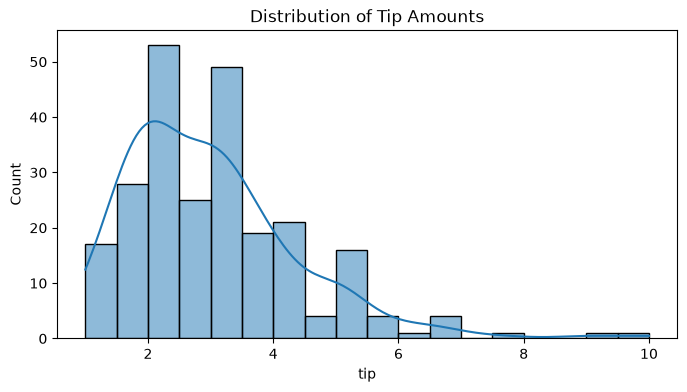

In [6]:
# Distribution of tip amounts
plt.figure(figsize=(8, 4))
sns.histplot(tips_df['tip'], kde=True)
plt.title("Distribution of Tip Amounts")

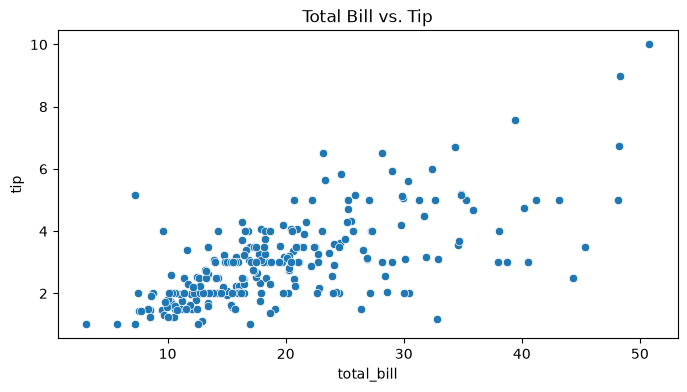

In [7]:
plt.figure(figsize=(8, 4))
sns.scatterplot(x='total_bill', y='tip', data=tips_df)
plt.title('Total Bill vs. Tip')
plt.show()

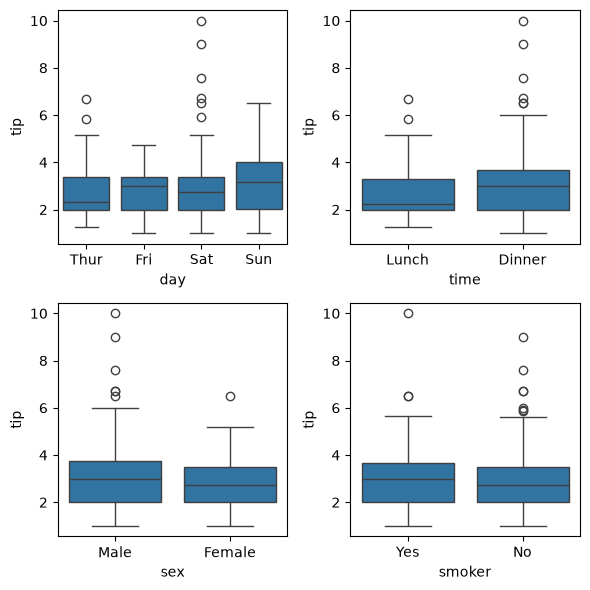

In [10]:
# Box plots for categorical variables
fig, axes = plt.subplots(2, 2, figsize=(6, 6))
sns.boxplot(x='day', y='tip', data=tips_df, ax=axes[0, 0])
sns.boxplot(x='time', y='tip', data=tips_df, ax=axes[0, 1])
sns.boxplot(x='sex', y='tip', data=tips_df, ax=axes[1, 0])
sns.boxplot(x='smoker', y='tip', data=tips_df, ax=axes[1, 1])
plt.tight_layout()
plt.show()

❓ **Key Insights:** 
- Note the distribution of tips. Is it normally distributed?
- Observe the relationship between total bill and tip. Does it appear linear?
- Look for any patterns in tipping based on categorical variables.


🔑 **Answers:**
- Tip distribution: Tip amounts are right-skewed, not perfectly normally distributed. Most tips are in the lower-to-middle range, with a few unusually large tips.
- Total bill and tip: There is a positive, roughly linear relationship, larger bills generally come with larger tips. The relationship is not exact, and tips vary considerably for bills of similar size.
- Categorical variables: Tip amounts vary somewhat across categories. Dinner and weekend meals tend to have higher absolute tips, while differences by sex and smoker status are less pronounced. These are associations in this dataset, not evidence that the categories cause different tipping behavior.